# Supervised Learning - Classification de cellules sanguines

- Dataset de **17 092 images RGB** de cellules sanguines périphériques acquises par microscopie.

- **8 classes** : neutrophile, éosinophile, basophile, lymphocyte, monocyte, immature granulocyte, érythroblaste, plaquette.

- Images "annoncées": 360×363px.

- Image acquise avec CellaVision DM96: un analyseur automatisé qui centre automatiquement, standardise le grossissement pour chaque type cellulaire et isole une cellule par image.

Lien: [Dataset Kaggle](https://www.kaggle.com/datasets/unclesamulus/blood-cells-image-dataset/discussion/507729)

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from sklearn.model_selection import train_test_split

print('Numpy:', np.__version__)
print('Pandas:', pd.__version__)

Numpy: 2.4.2
Pandas: 3.0.1


In [2]:
DATA_DIR = "../Dataset/bloodcells_dataset"

classes = sorted(os.listdir(DATA_DIR))
print('Classes trouvées :', classes)
print('Nombre de classes :', len(classes))

Classes trouvées : ['basophil', 'eosinophil', 'erythroblast', 'ig', 'lymphocyte', 'monocyte', 'neutrophil', 'platelet']
Nombre de classes : 8


# EDA :

- Dans les prochains modules nous allons analyser les différents données du dataset afin de comprendre ce que nous allons devoir faire dans le pre-processing des images :

- En premier lieux nous allons regarder la **repartition des classe** dans le dataset.

- Ensuite nous allons étudier **la tailles et la couleur** des images.

- Enfin nous allons voir si il existe des **critères discriminants** au dataset.


# EDA: REPARTITION

basophil: 1218 images
eosinophil: 3117 images
erythroblast: 1551 images
ig: 2895 images
lymphocyte: 1214 images
monocyte: 1420 images
neutrophil: 3329 images
platelet: 2348 images


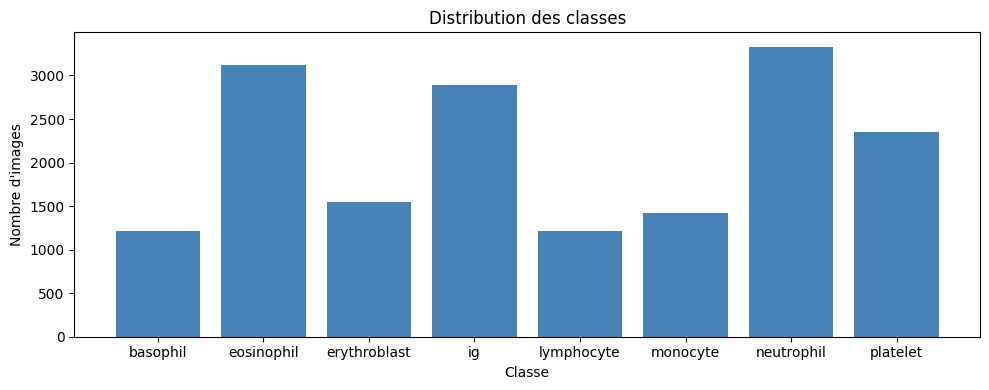

In [3]:
class_counts = {}
for cls in classes:
    class_counts[cls] = len(os.listdir(os.path.join(DATA_DIR, cls)))
    print(f"{cls}: {class_counts[cls]} images")

plt.figure(figsize=(10, 4))
plt.bar(class_counts.keys(), class_counts.values(), color='steelblue')
plt.title('Distribution des classes')
plt.xlabel('Classe')
plt.ylabel("Nombre d'images")
plt.tight_layout()
plt.show()



## Observation sur la repartition

- **unbalanced**: 2 groupes plus ou moins distincts.-> groupe entre 1000 et 1500 samples et autre groupe avec entre 2500 et 3000 samples (*2)

- **weighted loss** ?

# EDA: TAILLE ET COULEURS

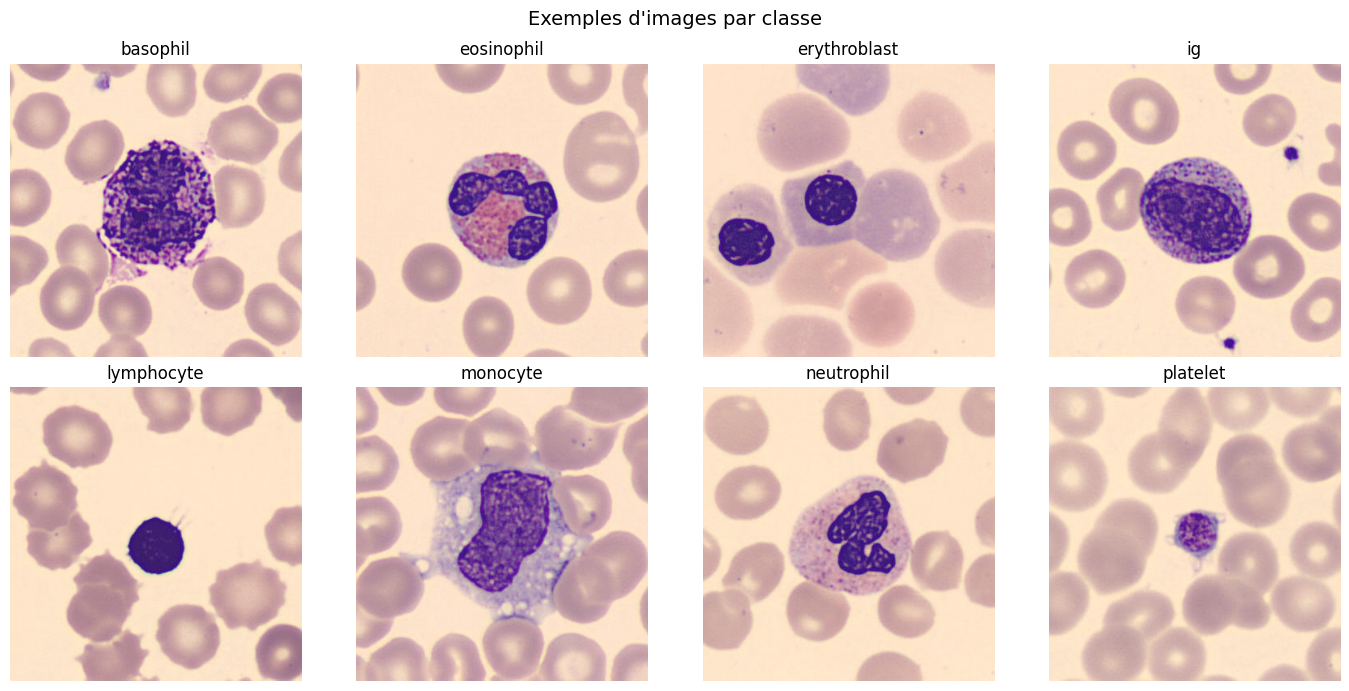

In [4]:
fig, axes = plt.subplots(2, 4, figsize=(14, 7))
axes = axes.flatten()

for i, cls in enumerate(classes):
    img_path = os.path.join(DATA_DIR, cls, os.listdir(os.path.join(DATA_DIR, cls))[0])
    img = Image.open(img_path)
    axes[i].imshow(img)
    axes[i].set_title(cls)
    axes[i].axis('off')

plt.suptitle("Exemples d'images par classe", fontsize=14)
plt.tight_layout()
plt.show()

In [5]:
wrong_sizes = []
wrong_mode = []
first_size = None

for cls in classes:
    cls_dir = os.path.join(DATA_DIR, cls)
    for fname in os.listdir(cls_dir):
        img = Image.open(os.path.join(cls_dir, fname))
        if first_size is None:
            first_size = img.size
        if img.size != first_size:
            wrong_sizes.append(f"{cls}/{fname}: {img.size}")
        if img.mode != 'RGB':
            wrong_mode.append(f"{cls}/{fname}: {img.mode}")

print(f"Taille de référence : {first_size}")
print(f"Images mal dimensionnées : {len(wrong_sizes)}")
print(f"Images non RGB : {len(wrong_mode)}")

if not wrong_sizes and not wrong_mode:
    print("Toutes les images ont la même taille et sont en RGB.")

Taille de référence : (360, 363)
Images mal dimensionnées : 453
Images non RGB : 0


## Observation sur la taille des images :

- on observe que toutes les images n'ont pas la meme dimensions aussi on voit que la taille référence et celle annoncé sur la page du dataset sont trop grosse pour sklearn (plus de **300 par 300 par 3 pixels par image**) sans utiliser un cnn avec pytorch on doit se conformer a une **limite de 64 ou 128 pixels** donc il faudra redimensionner.

- De plus les images sont en couleurs donc **255 valeurs** pour les 3 valeurs de chaque pixels donc on convertie entre 0 et 1 rgb


# EDA: DISCRIMINATION

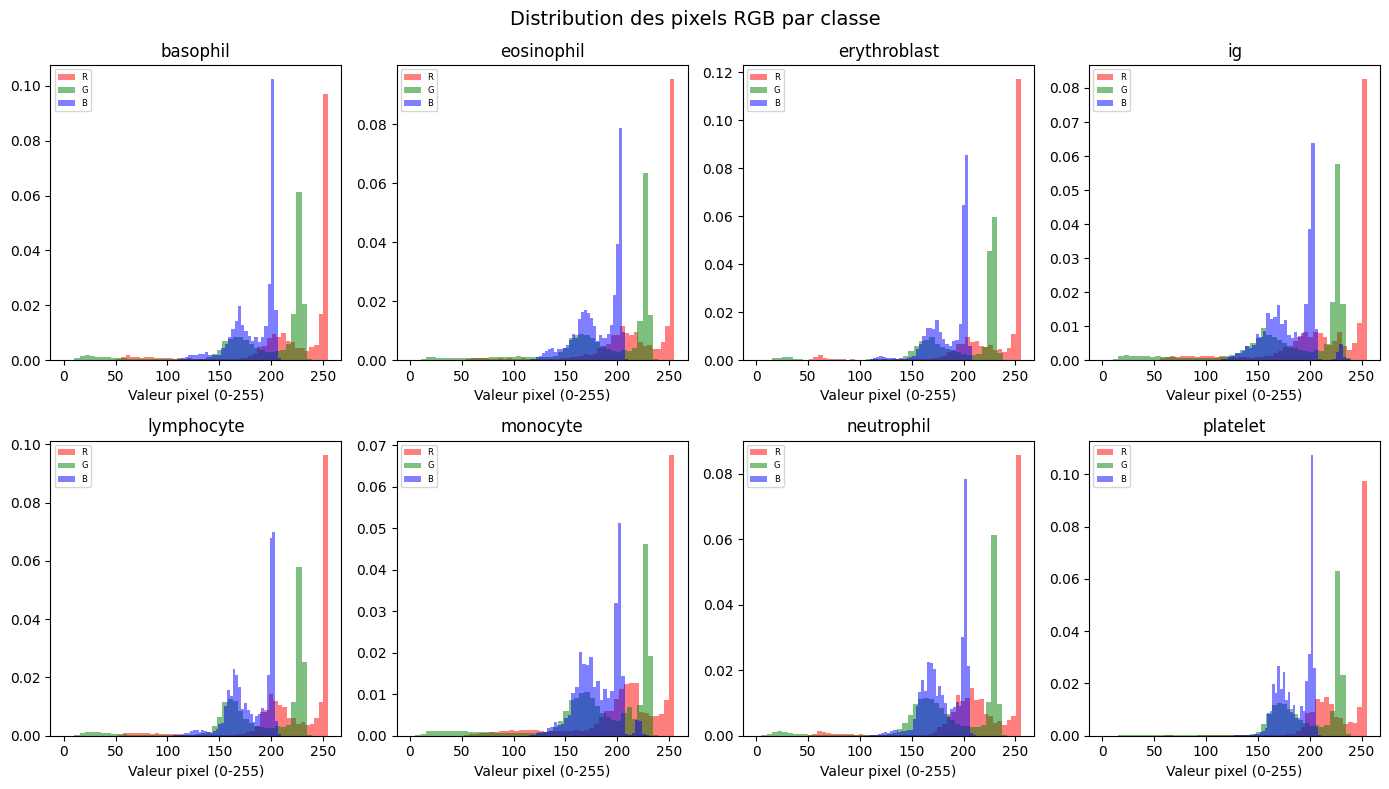

In [9]:
fig, axes = plt.subplots(2, 4, figsize=(14, 8))
axes = axes.flatten()

for i, cls in enumerate(classes):
    cls_dir = os.path.join(DATA_DIR, cls)
    pixels_r, pixels_g, pixels_b = [], [], []

    for fname in os.listdir(cls_dir)[:20]:
        img = np.array(Image.open(os.path.join(cls_dir, fname)))
        pixels_r.extend(img[:, :, 0].flatten())
        pixels_g.extend(img[:, :, 1].flatten())
        pixels_b.extend(img[:, :, 2].flatten())

    axes[i].hist(pixels_r, bins=50, color='red',   alpha=0.5, label='R', density=True)
    axes[i].hist(pixels_g, bins=50, color='green', alpha=0.5, label='G', density=True)
    axes[i].hist(pixels_b, bins=50, color='blue',  alpha=0.5, label='B', density=True)
    axes[i].set_title(cls)
    axes[i].set_xlabel('Valeur pixel (0-255)')
    axes[i].legend(fontsize=6)

plt.suptitle('Distribution des pixels RGB par classe', fontsize=14)
plt.tight_layout()
plt.show()


## Analyse De La Repartition RGB

- On constate que les différents graphe se ressemble et les cellules se confondent aux **bruits généré par le fond blanc commun** a toutes les classes -> on peut sans doute utilise une analyse en Composantes principales **PCA** pour isoler les informations spécifique aux classes (ignorant le fond blanc et ses perturbations)

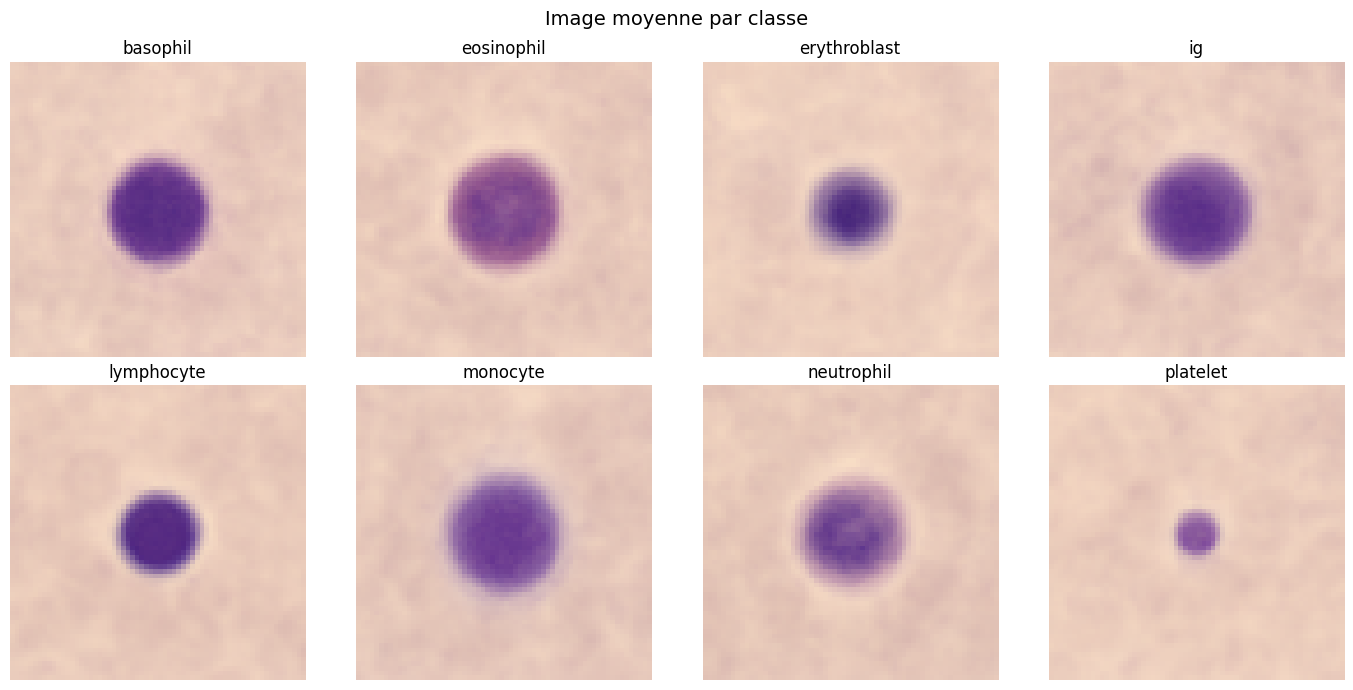

In [10]:
fig, axes = plt.subplots(2, 4, figsize=(14, 7))
axes = axes.flatten()

for i, cls in enumerate(classes):
    cls_dir = os.path.join(DATA_DIR, cls)
    images = []

    for fname in os.listdir(cls_dir)[:50]:
        img = np.array(Image.open(os.path.join(cls_dir, fname)).resize((64, 64)))
        images.append(img)

    mean_img = np.mean(images, axis=0).astype(np.uint8)
    axes[i].imshow(mean_img)
    axes[i].set_title(cls)
    axes[i].axis('off')

plt.suptitle("Image moyenne par classe", fontsize=14)
plt.tight_layout()
plt.show()


## Analyse De l'Image Moyenne Par Classe

- On sait aussi que chaque image est prise avec le meme degrè degrossissement donc la taille est représentative et constitue un facteur discriminant pour les classes.

In [13]:
X = []
Y = []

for i, cls in enumerate(classes):
    cls_dir = os.path.join(DATA_DIR, cls)
    for fname in os.listdir(cls_dir):
        img = np.array(Image.open(os.path.join(cls_dir, fname)).resize((64, 64))) / 255.0
        X.append(img)
        Y.append(i)

X = np.array(X) #4 dim
Y = np.array(Y) #1 dim -> N dim img

print(f"X shape: {X.shape}, dtype: {X.dtype}")
print(f"Y shape: {Y.shape}")


X shape: (17092, 64, 64, 3), dtype: float64
Y shape: (17092,)


In [ ]:
for i, cls in enumerate(classes):
    print(f"{i} -> {cls}")

0 -> basophil
1 -> eosinophil
2 -> erythroblast
3 -> ig
4 -> lymphocyte
5 -> monocyte
6 -> neutrophil
7 -> platelet


In [14]:
X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=0.2, stratify=y)
print(f"Train: {X_train.shape}, Test: {X_test.shape}")

Train: (13673, 64, 64, 3), Test: (3419, 64, 64, 3)
